# Triển khai trên Google Colab – Version 0 (CPU tuần tự)

V0 chỉ chạy trên CPU nên build bằng `g++`, không cần GPU. Chọn `Runtime → Run all`.

- **Mã nguồn:** tải thư mục repo (chứa `src/`) từ link Google Drive chung của nhóm (`REPO_DRIVE_URL`, chia sẻ *Anyone with the link*) về `/content/repo`, rồi build từ `src/`. Khi được báo cáo gọi, notebook dùng luôn mã nguồn báo cáo đã tải.
- **Dataset:** tải thẳng từ thư mục Google Drive bằng `gdown` (thư mục phải chia sẻ *Anyone with the link*), lưu vào `/content/dataset`.
- **Dùng từ báo cáo:** `Group07_Midterm.ipynb` chạy notebook này bằng `%run` với `EMBEDDED = True`. Khi đó notebook chỉ tính toán và lưu kết quả; bảng và hình được báo cáo hiển thị ở từng mục bằng các hàm `show_*`. Mở notebook này trực tiếp thì mọi kết quả hiển thị ngay tại chỗ.
- `PAIR_DIR`: đường dẫn tới **thư mục** của một cặp ảnh. Chương trình tự lấy 2 file `*.png` trong thư mục đó, sắp theo tên: file đứng trước là ảnh trái (A), file đứng sau là ảnh phải (B).

In [1]:
DATASET_URL = "https://drive.google.com/drive/folders/1eWi9OBGeIYzuW7wOhOMybv0-ZHNS6YrO"
RUNS = 5                                       # số lần đo (+1 lần warm-up)
REPO_DRIVE_URL = globals().get("REPO_DRIVE_URL", "")   # link thư mục Drive chung của nhóm chứa src/
REPO_DIR = globals().get("REPO_DIR", "")      # đã có khi được báo cáo gọi; để trống: tải từ REPO_DRIVE_URL
EMBEDDED = globals().get("EMBEDDED", False)    # True khi Group07_Midterm.ipynb chạy notebook này bằng %run

## 1. Lấy mã nguồn (src/) và dữ liệu

In [2]:
import glob, os, re, subprocess, time
from IPython.display import Image, display
%cd -q /content

def download_repo(url, out="/content/repo"):
    """Tải thư mục repo từ Google Drive về out (bỏ qua nếu đã tải), trả về thư mục chứa src/."""
    import gdown
    assert url, "Chưa điền REPO_DRIVE_URL"
    find = lambda: sorted(glob.glob(os.path.join(out, "**", "src", "main.cu"), recursive=True))
    if not find():
        print("Đang tải mã nguồn từ Google Drive...")
        gdown.download_folder(url, output=out, quiet=True)
    assert find(), f"Thư mục Drive không có src/main.cu: {url}"
    return os.path.dirname(os.path.dirname(find()[0]))

REPO_DIR = REPO_DIR or download_repo(REPO_DRIVE_URL)
print(f"Mã nguồn: {REPO_DIR}/src")

def download_dataset(url, out="dataset", tries=3):
    """Tải thư mục dataset bằng gdown. Google có thể tạm chặn khi một file bị tải nhiều lần
    ("many accesses"), nên tải lại phần còn thiếu (--continue) tối đa `tries` lần."""
    done = os.path.join(out, ".complete")          # chỉ tạo khi gdown tải xong toàn bộ
    if os.path.isfile(done):
        print("Dataset đã có trong /content/dataset, bỏ qua bước tải.")
        return
    cmd = ["gdown", "-q", "--folder", url, "-O", out, "--remaining-ok", "--continue"]
    for k in range(1, tries + 1):
        print(f"Đang tải dataset từ Google Drive (lần {k}/{tries})...")
        p = subprocess.run(cmd, capture_output=True, text=True)
        if "--continue" in cmd and "unrecognized arguments" in p.stderr:   # gdown cũ chưa có --continue
            cmd.remove("--continue")
            p = subprocess.run(cmd, capture_output=True, text=True)
        if p.returncode == 0:
            open(done, "w").close()
            return
        print("  Chưa tải xong:", (p.stderr.strip().splitlines() or ["không rõ lỗi"])[-1])
        if k < tries:
            time.sleep(30)
    raise RuntimeError("Không tải đủ dataset: kiểm tra quyền chia sẻ (Anyone with the link) hoặc đợi vài phút rồi chạy lại cell")

download_dataset(DATASET_URL)

PAIR_DIRS = sorted(d for d in {os.path.dirname(p) for p in glob.glob("/content/dataset/**/*.png", recursive=True)}
                   if len(glob.glob(os.path.join(d, "*.png"))) == 2)
print(f"  -> Xong: {len(PAIR_DIRS)} cặp ảnh trong /content/dataset")

Đang clone mã nguồn từ GitHub...
  -> Xong: /content/project
Đang tải dataset từ Google Drive...
  -> Xong: 30 cặp ảnh trong /content/dataset


## 2. Build chương trình

In [3]:
!g++ -O3 -std=c++17 -x c++ "{REPO_DIR}/src/main.cu" -x none "{REPO_DIR}"/src/*.cpp -o stitch && echo "BUILD OK: /content/stitch"

BUILD OK: /content/stitch


## 3. Ghép cặp chỉ định

`pair_images` lấy 2 file `*.png` trong `PAIR_DIR` (báo lỗi nếu thư mục không có đúng 2 ảnh), rồi gọi
`./stitch <trái> <phải> <output> --version 0 --runs RUNS`. Cell hiển thị ảnh trái và ảnh phải, ảnh panorama **không crop** (chạy thêm 1 lần với `--no-crop`, giữ vùng đen để thấy hình dạng hai ảnh sau khi warp), ảnh panorama **có crop**, rồi bảng thời gian từng stage (đo trên lần chạy có crop).

Ảnh trái và ảnh phải:



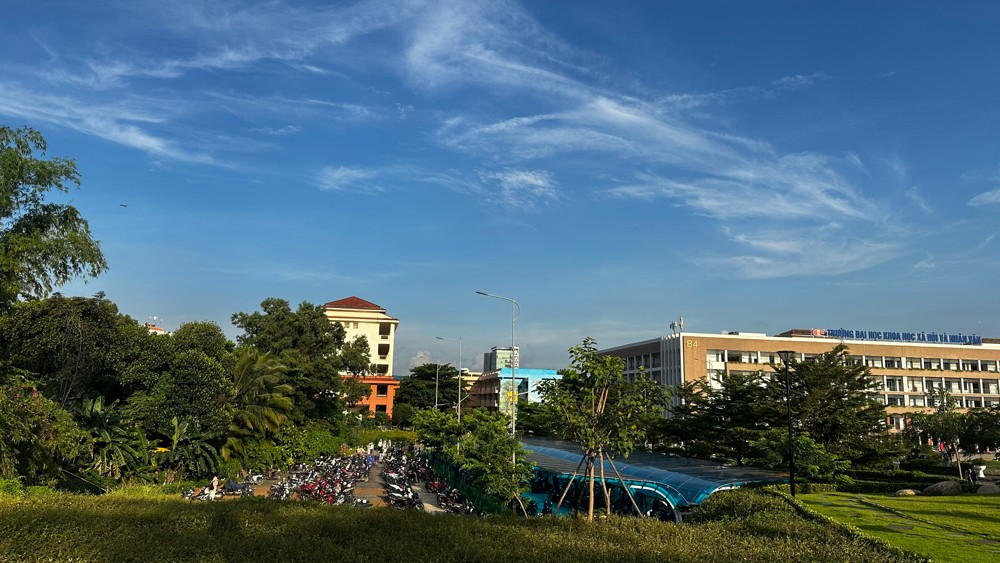
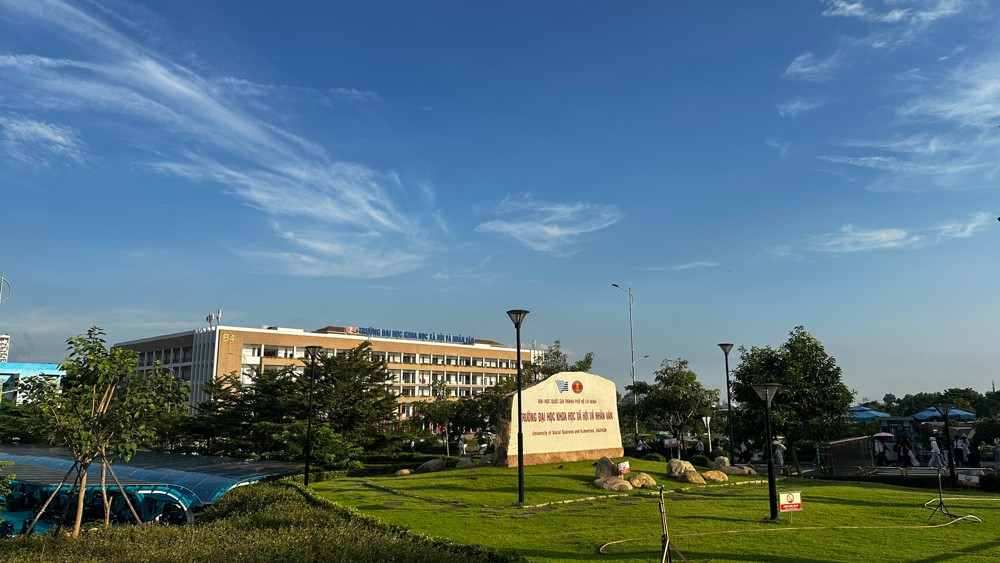


Ảnh panorama (không crop, giữ vùng đen):



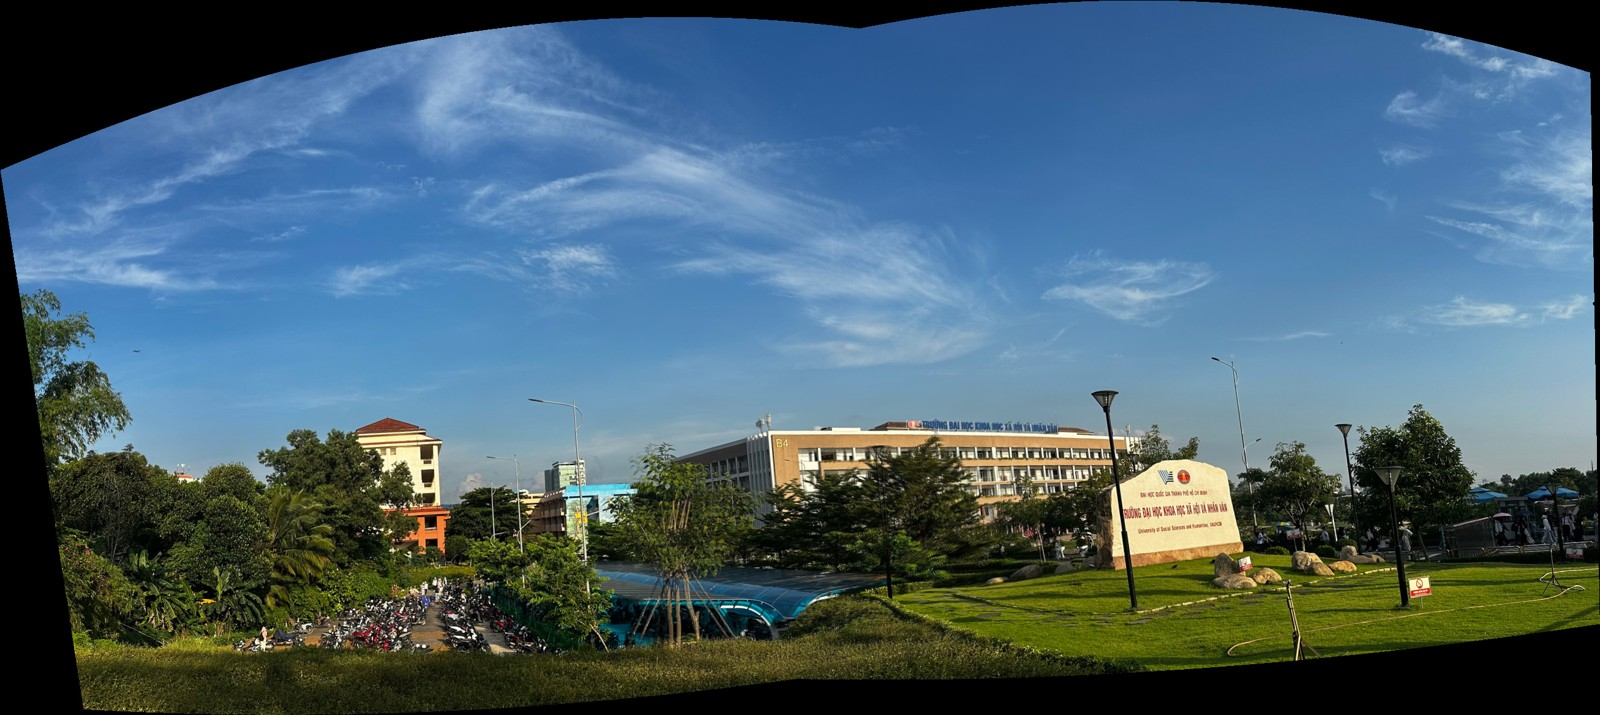


Ảnh panorama (crop về hình chữ nhật lớn nhất không có pixel đen):



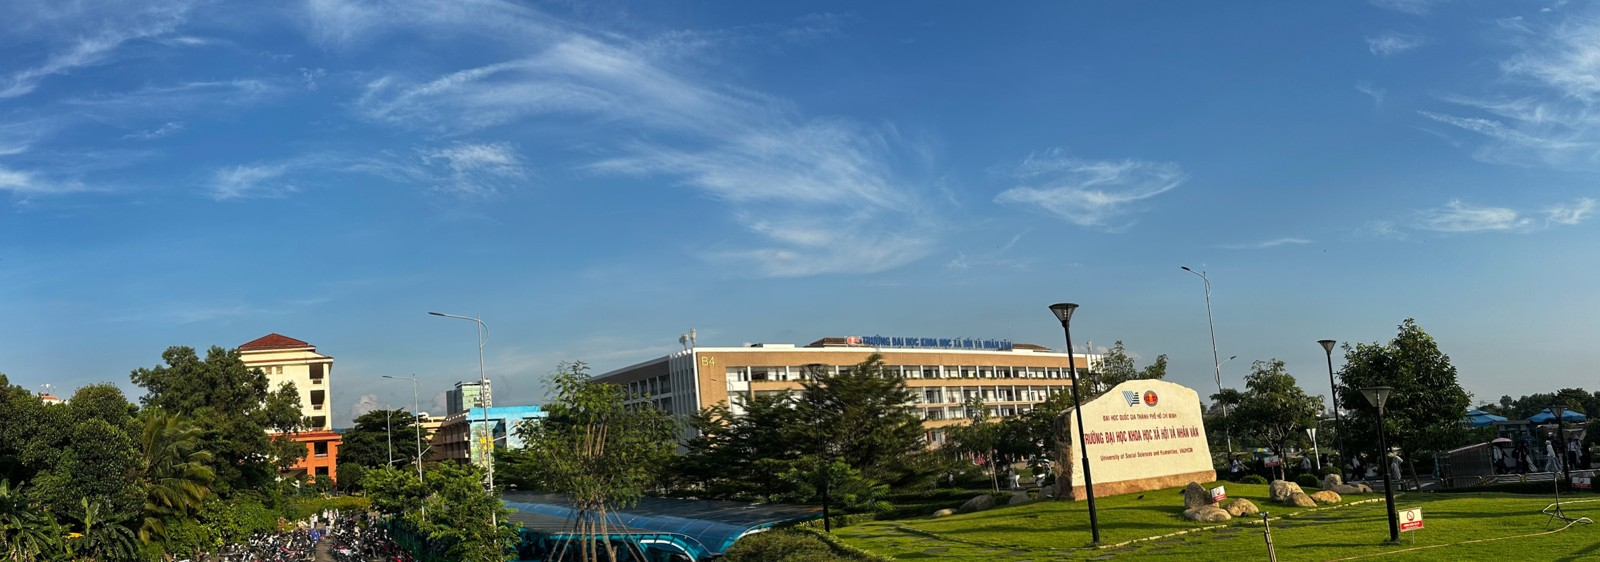

Image size: 1920x1080 + 1920x1080, version V0, 5 run(s)
Stage                          avg (ms)     min (ms)
----------------------------------------------------
1. Preprocessing                108.340      101.377
2. Keypoint detection           259.358      250.569
3. Description                   18.179       17.943
4. Matching                     216.657      215.182
5. Homography (RANSAC)            2.654        2.620
6. Warping & blending           346.887      344.526
----------------------------------------------------
Total (end-to-end)              952.075      944.224

[Success] Panorama 2371x833 saved to /content/panorama.jpg


In [4]:
import base64, io
from IPython.display import HTML
from PIL import Image as PILImage

PAIR_DIR = "/content/dataset/medium/standard pairs/Outdoor/Pair 1"   # thư mục chứa 2 ảnh .png cần ghép

def pair_images(pair_dir):
    imgs = sorted(glob.glob(os.path.join(pair_dir, "*.png")))
    assert len(imgs) == 2, f"'{pair_dir}' cần có đúng 2 ảnh .png (đang có {len(imgs)})"
    return imgs

def stitch(pair_dir, out, runs=RUNS, crop=True):
    left, right = pair_images(pair_dir)
    cmd = ["./stitch", left, right, out, "--version", "0", "--runs", str(runs)]
    return subprocess.run(cmd if crop else cmd + ["--no-crop"], capture_output=True, text=True)

def figure(path, max_w=1000, caption=None):
    # Thu nhỏ thành JPEG trong bộ nhớ để notebook không bị nặng với ảnh 4K
    img = PILImage.open(path).convert("RGB")
    size = f"{img.width}×{img.height}"
    img.thumbnail((max_w, max_w))
    buf = io.BytesIO()
    img.save(buf, "JPEG", quality=90)
    src = base64.b64encode(buf.getvalue()).decode()
    return (f'<figure style="flex:1; margin:0; text-align:center">'
            f'<img src="data:image/jpeg;base64,{src}" style="width:100%; height:auto">'
            f'<figcaption>{caption or os.path.basename(path)} ({size})</figcaption></figure>')

if not EMBEDDED:   # chỉ để minh họa khi mở notebook trực tiếp, báo cáo không dùng
    left, right = pair_images(PAIR_DIR)
    print("Ảnh trái và ảnh phải:")
    display(HTML(f'<div style="display:flex; gap:32px; max-width:1400px">{figure(left)}{figure(right)}</div>'))

    p = stitch(PAIR_DIR, "/content/panorama.jpg")                                # đo thời gian (có crop)
    q = stitch(PAIR_DIR, "/content/panorama_nocrop.jpg", runs=1, crop=False)     # chỉ để xem toàn bộ canvas
    if p.returncode == 0 and q.returncode == 0:
        print("\nẢnh panorama (không crop, giữ vùng đen):")
        display(HTML(f'<div style="max-width:1400px">{figure("/content/panorama_nocrop.jpg", 1600, "Không crop")}</div>'))
        print("\nẢnh panorama (crop về hình chữ nhật lớn nhất không có pixel đen):")
        display(HTML(f'<div style="max-width:1400px">{figure("/content/panorama.jpg", 1600, "Có crop")}</div>'))
        lines = p.stdout.splitlines()
        print("\n".join(lines[next(i for i, l in enumerate(lines) if l.startswith("Image size")):]))
    else:
        print(p.stdout, p.stderr, q.stdout, q.stderr)

## 4. Kiểm tra độ chính xác với ground truth (cặp synthetic)

Theo hướng dẫn của thầy: lấy **một ảnh**, cắt ra hai ảnh có vùng chồng lấp, rồi **warp ảnh thứ hai bằng một homography do nhóm chọn**. Vì nhóm tự tạo nên biết chính xác homography thật $H_{true}$.

Ảnh gốc là panorama `synthetic/GT1.png` (hoặc `.jpg`) trong dataset.

1. Cắt **A** ở góc trên trái và **B₀** ở góc dưới phải của ảnh gốc, cùng kích thước $w \times h$, lệch nhau $(d_x, d_y)$ với $d_x = 0.35\,w$. Một điểm $p$ của B₀ là điểm $p + (d_x, d_y)$ của A:

$$T = \begin{bmatrix} 1 & 0 & d_x \\ 0 & 1 & d_y \\ 0 & 0 & 1 \end{bmatrix}$$

2. Nhóm chọn $G = K\,R\,K^{-1}$: camera xoay tại chỗ thêm yaw $5^\circ$, pitch $1^\circ$, roll $1^\circ$, với $K$ có tiêu cự $f = 0.72\,w$ và tâm ảnh là điểm chính.
3. Tạo **B** bằng inverse warping: $B(q) = B_0(G\,q)$, nội suy bilinear. Như vậy $G$ ánh xạ B → B₀.
4. Ground truth cùng chiều với H của chương trình (B → A):

$$H_{true} = T\,G, \qquad \text{chuẩn hóa } h_{33} = 1.$$

5. Chạy V0 trên (A, B) để có $H_{V0}$, rồi so với $H_{true}$.

**Độ đo** (tính trên các điểm của ảnh B, đơn vị là pixel của ảnh A):
- **ACE** (Average Corner Error): trung bình của $\lVert H_{V0}\,c - H_{true}\,c \rVert$ trên 4 góc $c$ của ảnh B.
- **Max corner:** sai số lớn nhất trong 4 góc trên.
- **RMSE overlap:** căn bậc hai trung bình bình phương sai số trên lưới 160×90 điểm của B, chỉ lấy những điểm mà $H_{true}$ chiếu vào bên trong A, tức vùng thực sự được ghép.

In [ ]:
import numpy as np
import pandas as pd

# ---- Cặp synthetic: cắt A, B0 từ một ảnh, warp B0 bằng G do nhóm chọn ----
SHIFT, VSHIFT = 0.35, 0.01           # B0 lệch 35% chiều rộng và 1% chiều cao so với A
YAW, PITCH, ROLL = 5.0, 1.0, 1.0     # G: camera xoay thêm (độ)
F_RATIO = 0.72                       # tiêu cự f = 0.72 * w

# Pillow lấy tâm pixel i ở tọa độ i + 0.5, còn ./stitch dùng chỉ số pixel: C đổi chỉ số -> tọa độ Pillow.
C = np.array([[1, 0, 0.5], [0, 1, 0.5], [0, 0, 1]])

def normalized(h):
    return h / h[2, 2]

def rotation_homography(w, h, yaw, pitch, roll, f_ratio=F_RATIO):
    """G = K R K^-1 của camera xoay tại chỗ, theo chỉ số pixel."""
    f = f_ratio * w
    K = np.array([[f, 0, (w - 1) / 2], [0, f, (h - 1) / 2], [0, 0, 1]])
    y, p, r = np.deg2rad([yaw, pitch, roll])
    Ry = np.array([[np.cos(y), 0, np.sin(y)], [0, 1, 0], [-np.sin(y), 0, np.cos(y)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(p), -np.sin(p)], [0, np.sin(p), np.cos(p)]])
    Rz = np.array([[np.cos(r), -np.sin(r), 0], [np.sin(r), np.cos(r), 0], [0, 0, 1]])
    return normalized(K @ Ry @ Rx @ Rz @ np.linalg.inv(K))

def warp_inverse(img, G, size):
    """B(q) = img(G q) với q là chỉ số pixel; Pillow PERSPECTIVE nhận đúng ánh xạ ảnh ra -> ảnh vào."""
    g = normalized(C @ G @ np.linalg.inv(C))
    return img.transform(size, PILImage.Transform.PERSPECTIVE, tuple(g.flatten()[:8]),
                         resample=PILImage.Resampling.BILINEAR)

def make_synthetic_pair(source, out_dir):
    """Ghi A.png, B.png vào out_dir; trả về H_true (B -> A) và các tham số đã dùng."""
    src = PILImage.open(source).convert("RGB")
    W, Hs = src.size
    w, h = round(W / (1 + SHIFT)), round(Hs / (1 + VSHIFT))
    dx, dy = W - w, Hs - h
    A = src.crop((0, 0, w, h))
    B0 = src.crop((dx, dy, dx + w, dy + h))
    G = rotation_homography(w, h, YAW, PITCH, ROLL)
    B = warp_inverse(B0, G, (w, h))
    T = np.array([[1, 0, dx], [0, 1, dy], [0, 0, 1]], dtype=float)
    os.makedirs(out_dir, exist_ok=True)
    A.save(os.path.join(out_dir, "A.png"))
    B.save(os.path.join(out_dir, "B.png"))
    return normalized(T @ G), {"src": (W, Hs), "size": (w, h), "shift": (dx, dy)}

# ---- Đọc output của ./stitch ----
def parse_run(stdout):
    """Đọc thống kê của lần warm-up và ma trận H (B -> A) từ output của ./stitch."""
    run = {}
    if m := re.search(r"(\d+) keypoints in A, (\d+) in B", stdout):
        run["kp_A"], run["kp_B"] = int(m[1]), int(m[2])
    if m := re.search(r"(\d+) inliers / (\d+) matches", stdout):
        run["inliers"], run["matches"] = int(m[1]), int(m[2])
    if m := re.search(r"H \(B -> A\)\s*: \[([^\]]+)\]", stdout):
        run["H"] = np.array(m[1].replace(";", " ").split(), dtype=float).reshape(3, 3)
    return run

# ---- Độ đo sai số của H_V0 so với H_true ----
def project(H, pts):
    q = np.c_[pts, np.ones(len(pts))] @ H.T
    return q[:, :2] / q[:, 2:]

def homography_errors(H_est, H_true, B_size, A_size):
    """Sai số (pixel ảnh A) khi chiếu các điểm của ảnh B bằng H_est thay cho H_true."""
    (w, h), (wA, hA) = B_size, A_size
    corners = np.array([[0, 0], [w - 1, 0], [0, h - 1], [w - 1, h - 1]], dtype=float)
    d = np.linalg.norm(project(H_est, corners) - project(H_true, corners), axis=1)
    grid = np.stack(np.meshgrid(np.linspace(0, w - 1, 160), np.linspace(0, h - 1, 90)), -1).reshape(-1, 2)
    gt = project(H_true, grid)
    inside = (gt[:, 0] >= 0) & (gt[:, 0] <= wA - 1) & (gt[:, 1] >= 0) & (gt[:, 1] <= hA - 1)
    e = np.linalg.norm(project(H_est, grid[inside]) - gt[inside], axis=1)
    return {"ACE (px)": d.mean(), "Max corner (px)": d.max(),
            "RMSE overlap (px)": np.sqrt(np.mean(e ** 2))}

Cell dưới tạo cặp synthetic từ ảnh gốc `GT_NAME`, chạy V0 rồi in $H_{true}$, $H_{V0}$ và bảng sai số. Sau đó cell hiển thị ảnh A, ảnh B và panorama V0 **không crop**.

Mép phải của B có một vùng đen: đó là các pixel mà $G\,q$ rơi ra ngoài B₀ nên không có dữ liệu. Vùng này không ảnh hưởng tới sai số, vì sai số được tính trên ma trận H.

In [ ]:
GT_NAME = "GT1"                                      # ảnh gốc: synthetic/<GT_NAME>.png hoặc .jpg

SYNTHETIC_DIR = "/content/dataset/synthetic"
found = [p for p in glob.glob(os.path.join(SYNTHETIC_DIR, GT_NAME + ".*"))
         if p.lower().endswith((".png", ".jpg", ".jpeg"))]
assert len(found) == 1, f"Cần đúng 1 ảnh {GT_NAME}.png/.jpg trong {SYNTHETIC_DIR} (đang có {len(found)})"
SYN_PAIR = f"/content/synthetic_pair/{GT_NAME}"      # A.png, B.png được tạo ở đây

H_true, info = make_synthetic_pair(found[0], SYN_PAIR)
(w, h), (dx, dy) = info["size"], info["shift"]

p = stitch(SYN_PAIR, f"/content/{GT_NAME}_nocrop.jpg", runs=1, crop=False)
assert p.returncode == 0, p.stdout + p.stderr
run = parse_run(p.stdout)
SYN_ERR = {"Cỡ ảnh": f"{w}×{h}", "Keypoint A / B": f'{run["kp_A"]} / {run["kp_B"]}',
           "Inlier / Match": f'{run["inliers"]} / {run["matches"]}',
           **homography_errors(run["H"], H_true, (w, h), (w, h))}


def show_synthetic():
    print(f"Ảnh gốc {os.path.basename(found[0])} ({info['src'][0]}×{info['src'][1]}) -> A, B cỡ {w}×{h}; "
          f"dx = {dx} px, dy = {dy} px")
    print(f"G: yaw {YAW}°, pitch {PITCH}°, roll {ROLL}°, f = {F_RATIO}·w = {F_RATIO * w:.1f} px")
    np.set_printoptions(precision=8, suppress=False)
    print(f"\nH_true =\n{H_true}\nH_V0 =\n{run['H']}")

    print("\nSai số của H_V0 so với H_true (pixel):")
    display(pd.DataFrame([SYN_ERR]).style.hide(axis="index").format(precision=3)
            .set_table_styles([{"selector": "th, td", "props": "padding: 6px 24px; text-align: center"}]))

    a_path, b_path = pair_images(SYN_PAIR)
    print("\nẢnh A và ảnh B (B = B₀ warp bằng G):")
    display(HTML(f'<div style="display:flex; gap:32px; max-width:1400px">{figure(a_path)}{figure(b_path)}</div>'))
    print("\nPanorama V0 (không crop, giữ vùng đen):")
    display(HTML(f'<div style="max-width:1400px">{figure(f"/content/{GT_NAME}_nocrop.jpg", 1600, "V0 – không crop")}</div>'))

if not EMBEDDED:
    show_synthetic()

## 6. Chạy toàn bộ dataset

Chạy V0 trên mọi cặp ảnh ở các độ phân giải trong `SIZES`:
- **Cặp chuẩn:** 1 lần warm-up + `RUNS` lần đo, dùng cho bảng thời gian.
- **Cặp thử thách:** chạy 1 lần, chỉ dùng để phân tích thất bại, không đưa vào bảng thời gian.

Kết quả lưu trong `ROWS` và được các mục 7–10 dùng lại, nên chỉ cần chạy một lần. Panorama được lưu vào `/content/out/<độ phân giải>/`. Ảnh large chạy khá lâu trên CPU của Colab; mỗi dòng in ra kèm thời gian thực của cặp đó để tiện theo dõi.

Cell đầu tiên chỉ khai báo hằng số và hàm dùng chung, không chạy V0.

In [7]:
import numpy as np
import pandas as pd

SIZES = ["small", "medium", "large"]                      # các độ phân giải cần chạy
DIMS = {"small": (1280, 720), "medium": (1920, 1080), "large": (3840, 2160)}
RES_LABEL = {s: f"{s} ({w}×{h})" for s, (w, h) in DIMS.items()}

STAGE_NAMES = ["1. Preprocessing", "2. Keypoint detection", "3. Description",
               "4. Matching", "5. Homography (RANSAC)", "6. Warping & blending"]   # tên giai đoạn trong output của ./stitch
STAGE_COLS = ["S1 Tiền xử lý", "S2 Keypoint", "S3 Mô tả", "S4 Ghép cặp", "S5 RANSAC", "S6 Warp + blend"]
TOTAL = "Total (end-to-end)"
STITCH_CMD = ["./stitch"]
TABLE_STYLE = [{"selector": "th, td", "props": "padding: 6px 16px; text-align: center; white-space: nowrap"}]

def show_table(df, fmt=None):
    """Hiển thị bảng: ẩn cột chỉ mục (mọi tiêu đề nằm cùng một hàng), căn giữa và giãn cột."""
    sty = df.style.hide(axis="index").format(precision=2, na_rep="–")
    if fmt:   # định dạng riêng chỉ áp lên các cột được chỉ định, các cột khác giữ 2 chữ số thập phân
        sty = sty.format(fmt, subset=list(fmt), na_rep="–")
    display(sty.set_table_styles(TABLE_STYLE))

def parse_output(text):
    """Đọc thống kê lần warm-up, ma trận H, kích thước panorama và thời gian (avg, min) từ output của ./stitch."""
    r = {}
    if m := re.search(r"(\d+) keypoints in A, (\d+) in B", text):
        r["kp_a"], r["kp_b"] = map(int, m.groups())
    if m := re.search(r"Stage 4 \(matching\)\s*:\s*(\d+) matches", text):
        r["matches"] = int(m[1])
    if m := re.search(r"Stage 5 \(RANSAC\)\s*:\s*(\d+) inliers", text):
        r["inliers"] = int(m[1])
    if m := re.search(r"H \(B -> A\)\s*:\s*\[([^\]]*)\]", text):
        r["H"] = np.array(m[1].replace(";", " ").split(), dtype=float).reshape(3, 3)
    if m := re.search(r"Panorama (\d+)x(\d+) saved", text):
        r["pano"] = f"{m[1]}×{m[2]}"
    for name in STAGE_NAMES + [TOTAL]:
        if m := re.search(rf"^{re.escape(name)}\s+([\d.]+)\s+([\d.]+)\s*$", text, re.M):
            r[name], r[name + " min"] = float(m[1]), float(m[2])
    return r

def run_v0(left, right, out, runs=RUNS, crop=True):
    args = [left, right, out, "--version", "0", "--runs", str(runs)] + ([] if crop else ["--no-crop"])
    p = subprocess.run(STITCH_CMD + args, capture_output=True, text=True)
    r = parse_output(p.stdout)
    r["ok"] = p.returncode == 0 and TOTAL in r
    r["log"] = p.stdout + p.stderr
    return r

def error_reason(r):
    """Dòng lỗi cụ thể của V0 (ví dụ RANSAC thất bại), nếu không có thì dòng cuối của log."""
    lines = r["log"].strip().splitlines()
    return next((l.strip() for l in lines if "[V0 Error]" in l), lines[-1] if lines else "")

In [8]:
import time

OUT_DIR = "/content/out"

def pair_info(d):
    """(độ phân giải, nhóm, tên cặp) từ đường dẫn, ví dụ ('medium', 'standard', 'Indoor / Pair 1')."""
    parts = os.path.relpath(d, "/content/dataset").split(os.sep)
    if len(parts) < 3:
        return parts[0], "", ""
    group = "challenge" if "challenge" in parts[1].lower() else "standard"
    return parts[0], group, " / ".join((["Challenge"] if group == "challenge" else []) + parts[2:])

ROWS = []
jobs = [(pair_info(d), d) for d in PAIR_DIRS if pair_info(d)[0] in SIZES]
jobs.sort(key=lambda j: (SIZES.index(j[0][0]), j[0][1] != "standard", j[0][2]))
for (size, group, label), d in jobs:
    out = os.path.join(OUT_DIR, size, re.sub(r"\W+", "_", label) + ".jpg")
    os.makedirs(os.path.dirname(out), exist_ok=True)
    t0 = time.time()
    r = run_v0(*pair_images(d), out, runs=RUNS if group == "standard" else 1)   # cặp thử thách không vào bảng thời gian
    r.update(size=size, group=group, pair=label, dir=d, out=out)
    ROWS.append(r)
    status = f"{r[TOTAL]:9.1f} ms" if r["ok"] else "   THẤT BẠI"
    print(f"{RES_LABEL[size]:19s} {label:20s} {status} | keypoint {r.get('kp_a', '–')}/{r.get('kp_b', '–')}, "
          f"cặp ghép {r.get('matches', '–')}, inlier {r.get('inliers', '–')}  ({time.time() - t0:.0f} s)")

failed = [r for r in ROWS if not r["ok"]]
print(f"\n{len(ROWS) - len(failed)}/{len(ROWS)} lần chạy thành công")
for r in failed:
    print(f"  THẤT BẠI {RES_LABEL[r['size']]} – {r['pair']}: {error_reason(r)}")

small (1280×720)    Indoor / Pair 1          498.6 ms | keypoint 906/647, cặp ghép 27, inlier 15  (3 s)
small (1280×720)    Indoor / Pair 2          587.2 ms | keypoint 1517/1170, cặp ghép 90, inlier 26  (4 s)
small (1280×720)    Indoor / Pair 3          468.3 ms | keypoint 1461/1556, cặp ghép 275, inlier 227  (3 s)
small (1280×720)    Outdoor / Pair 1         372.3 ms | keypoint 1168/956, cặp ghép 50, inlier 41  (2 s)
small (1280×720)    Outdoor / Pair 2         373.8 ms | keypoint 895/641, cặp ghép 34, inlier 27  (2 s)
small (1280×720)    Outdoor / Pair 3         686.2 ms | keypoint 2043/1028, cặp ghép 85, inlier 52  (4 s)
small (1280×720)    Outdoor / Pair 4         394.6 ms | keypoint 1264/1272, cặp ghép 154, inlier 135  (3 s)
small (1280×720)    Challenge / Pair 1       313.2 ms | keypoint 627/503, cặp ghép 92, inlier 85  (1 s)
small (1280×720)    Challenge / Pair 2       293.3 ms | keypoint 221/375, cặp ghép 26, inlier 10  (1 s)
medium (1920×1080)  Indoor / Pair 1          832.9 

## 7. Panorama đầu ra (Mục 5.2)

Panorama của mọi cặp ở độ phân giải `SHOW_SIZE`, kèm số keypoint, số cặp ghép và số inlier. Với cặp thất bại, cell in thông báo lỗi và hiển thị hai ảnh đầu vào để phục vụ phần phân tích thất bại.

Panorama V0 ở độ phân giải medium (1920×1080):



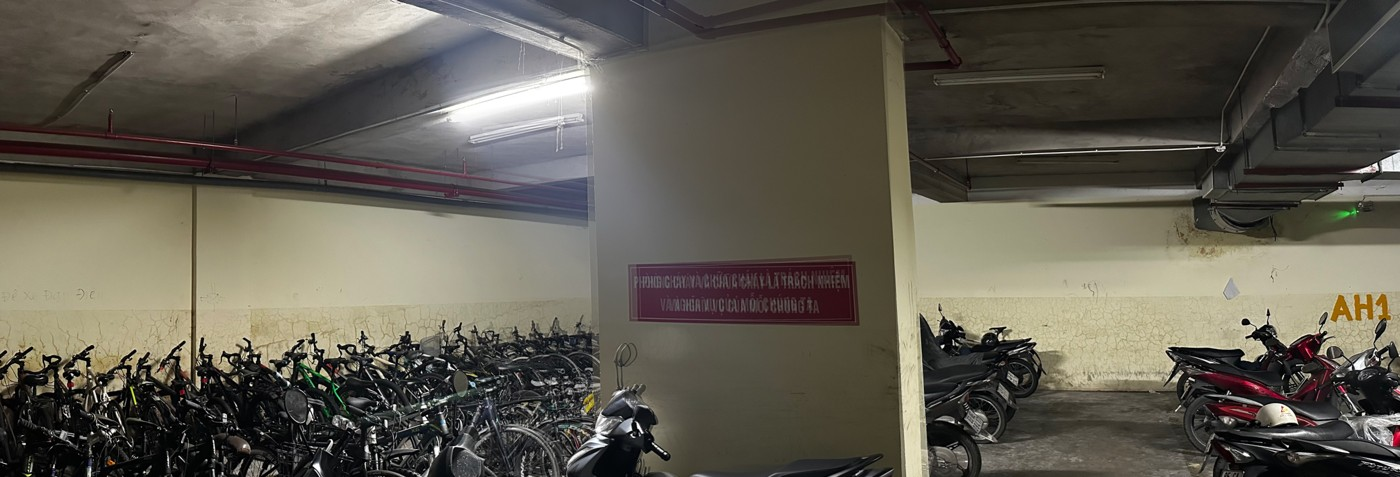


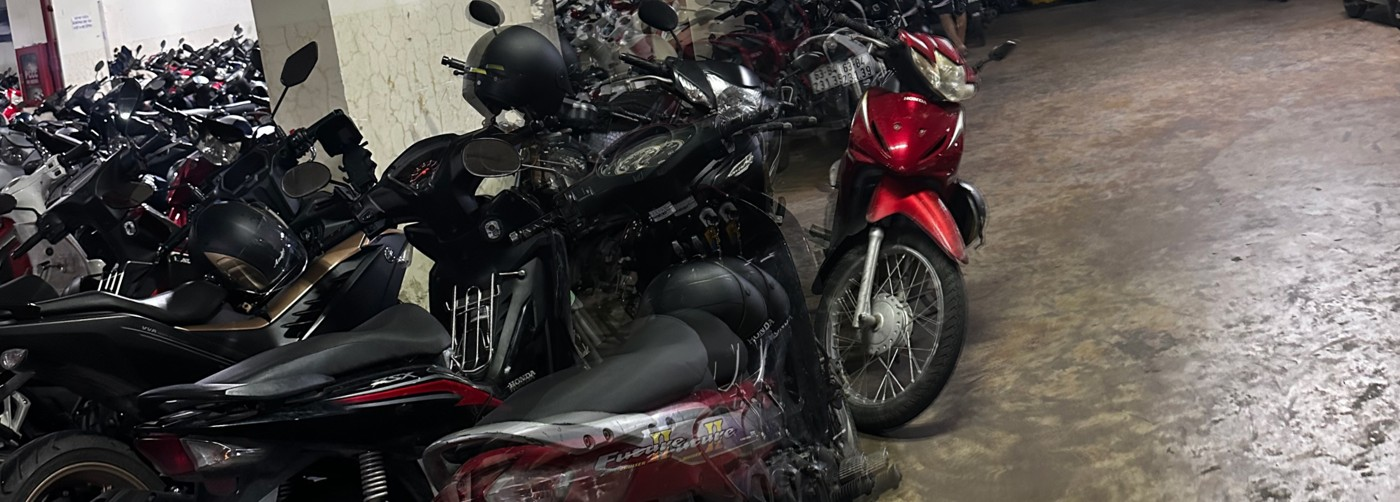


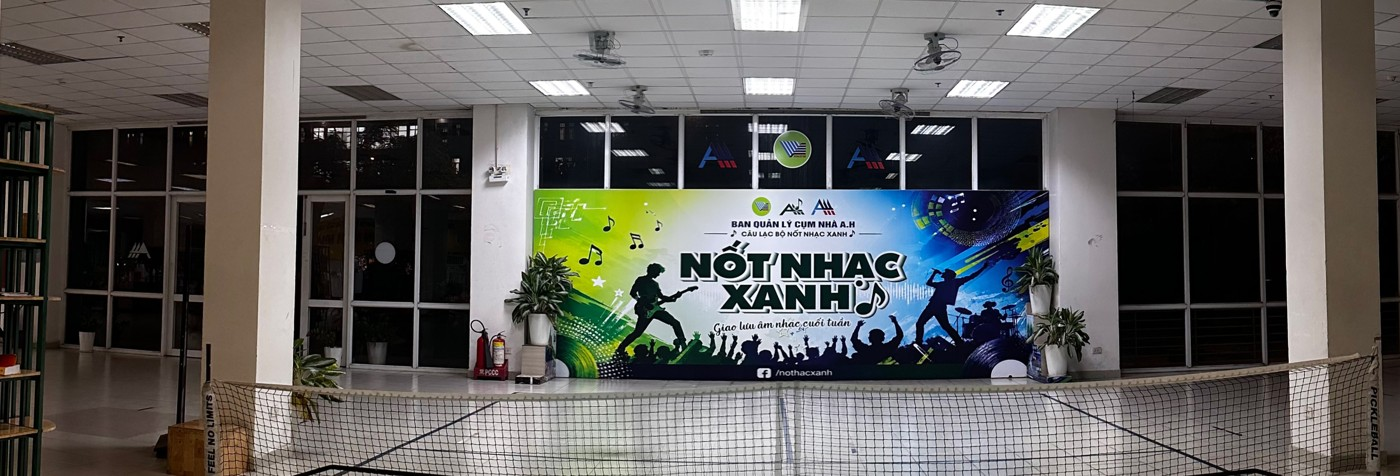


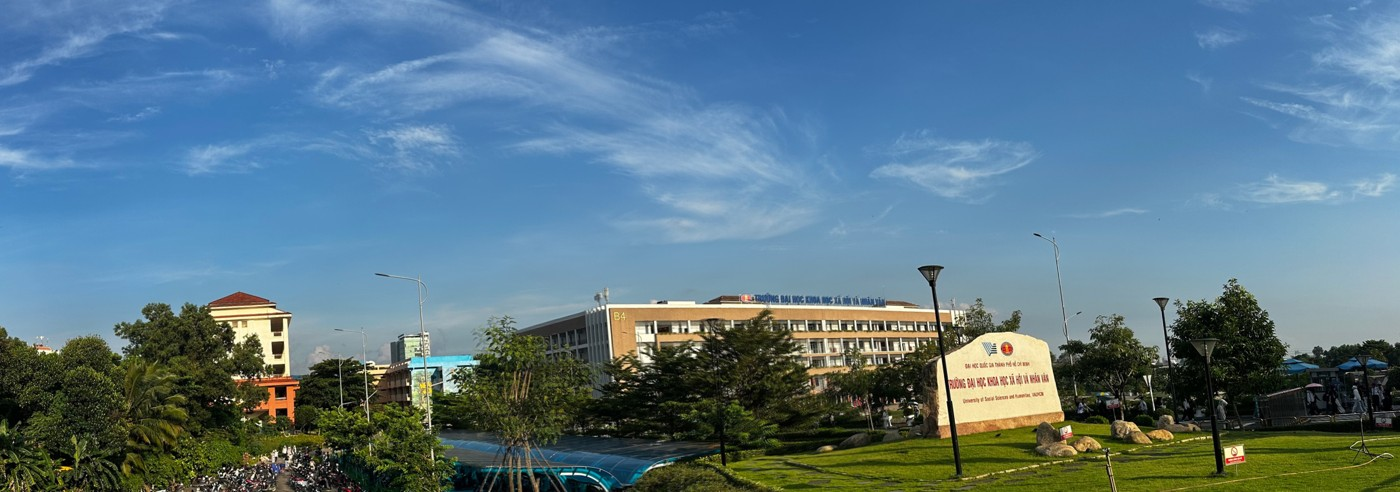


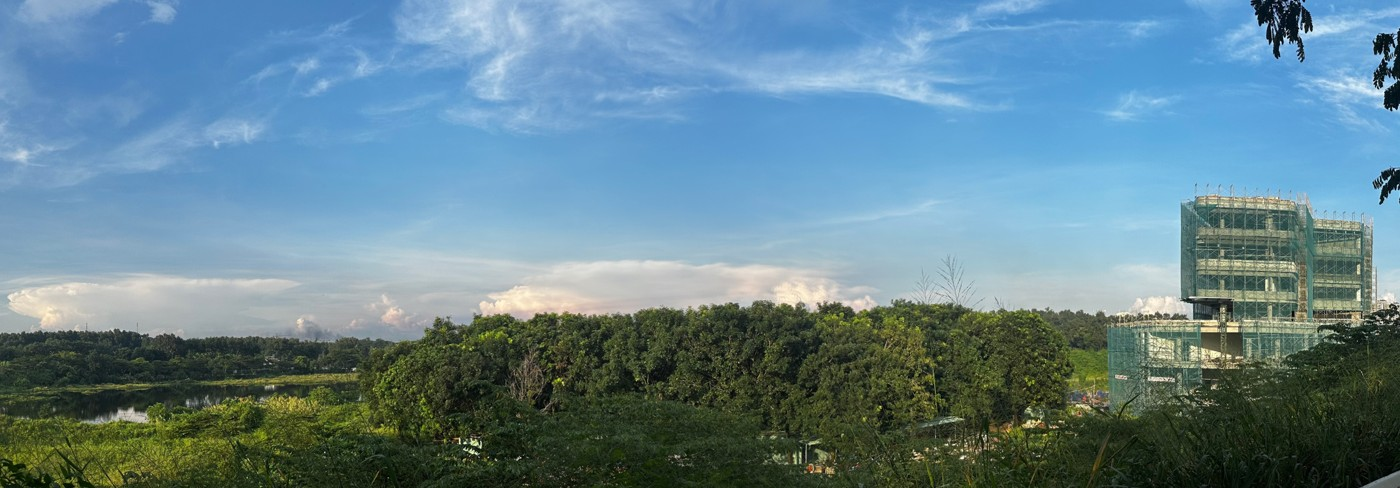


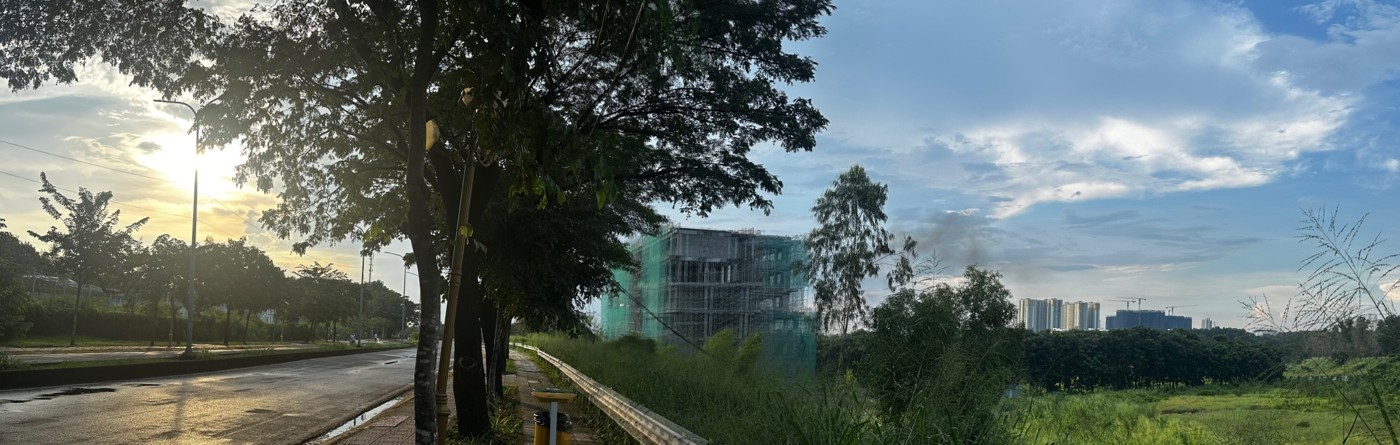


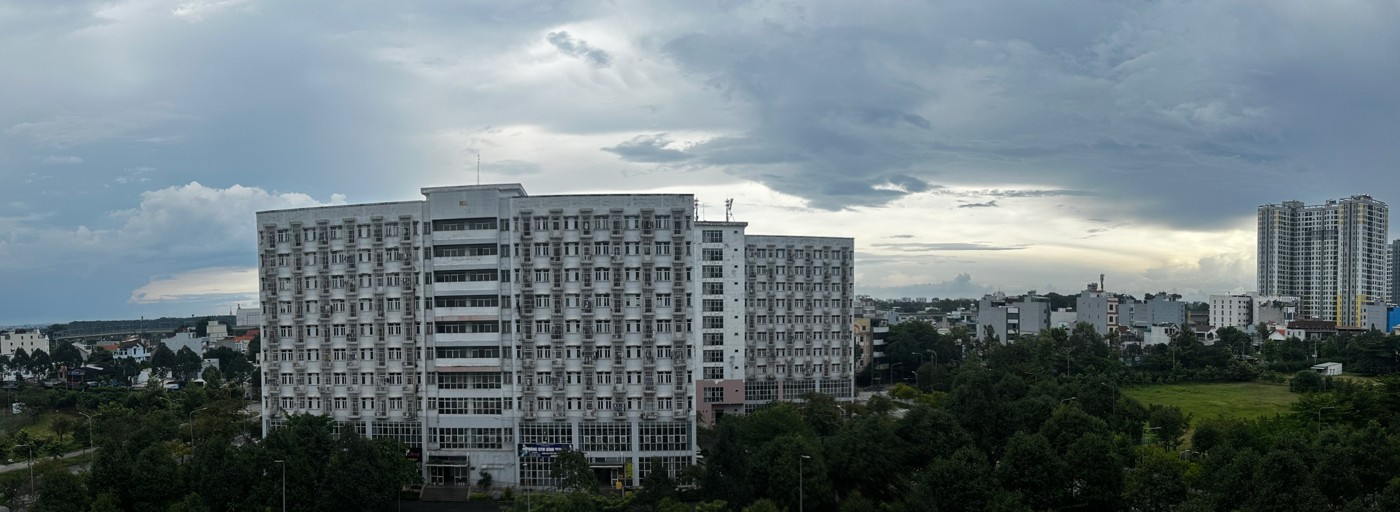


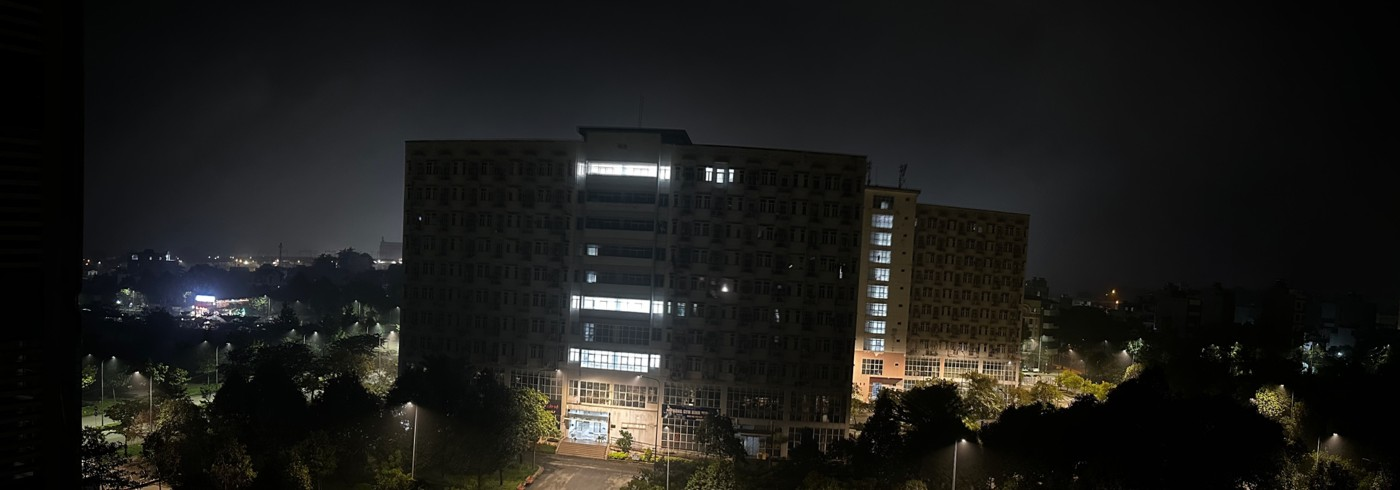


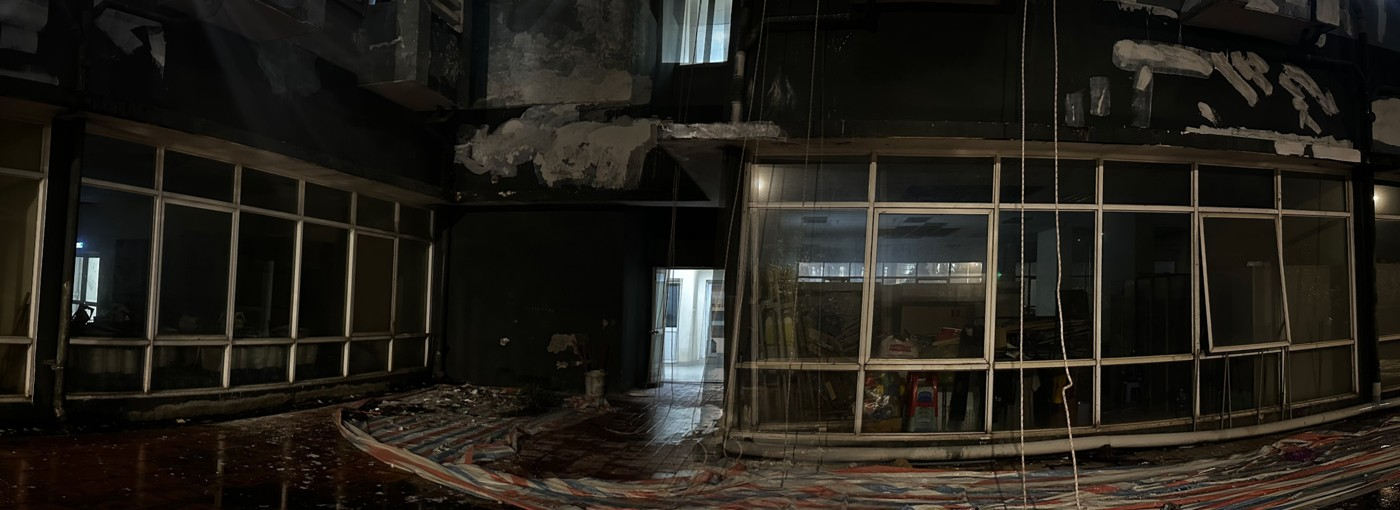

In [9]:
SHOW_SIZE = "medium"   # độ phân giải dùng để hiển thị panorama

def show_panoramas(size=SHOW_SIZE):
    print(f"Panorama V0 ở độ phân giải {RES_LABEL[size]}:")
    for r in (x for x in ROWS if x["size"] == size):
        info = (f"{r['pair']} – keypoint {r.get('kp_a', '–')}/{r.get('kp_b', '–')}, "
                f"cặp ghép {r.get('matches', '–')}, inlier {r.get('inliers', '–')}")
        if r["ok"]:
            display(HTML(f'<div style="max-width:1200px; margin-bottom:24px">{figure(r["out"], 1400, info)}</div>'))
        else:
            left, right = pair_images(r["dir"])
            print(f"\nTHẤT BẠI – {info}\n  {error_reason(r)}")
            display(HTML(f'<div style="display:flex; gap:32px; max-width:1200px">{figure(left)}{figure(right)}</div>'))

if not EMBEDDED:
    show_panoramas()

## 8. Bảng thời gian từng giai đoạn (Mục 5.3)

Thời gian trung bình của `RUNS` lần đo (ms), không gồm đọc/ghi ảnh.
- **Bảng 1:** trung bình trên các **cặp chuẩn** chạy thành công, mỗi cột là một độ phân giải.
- **Bảng 2:** chi tiết từng cặp. Cột *Keypoint* là trung bình số keypoint của A và B, dùng để giải thích thời gian của Giai đoạn 3–4.

Toàn bộ số liệu được lưu vào `/content/v0_timing.csv`.

In [10]:
import platform

try:
    cpu = next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name"))
except (OSError, StopIteration):
    cpu = platform.processor() or "không rõ"

df = pd.DataFrame([{"size": r["size"], "Độ phân giải": RES_LABEL[r["size"]], "Cặp": r["pair"],
                    "Keypoint": (r["kp_a"] + r["kp_b"]) / 2, "Cặp ghép": r["matches"], "Inlier": r["inliers"],
                    **{c: r[s] for c, s in zip(STAGE_COLS, STAGE_NAMES)}, "Tổng": r[TOTAL], "Tổng (min)": r[TOTAL + " min"]}
                   for r in ROWS if r["ok"] and r["group"] == "standard"])
df.drop(columns="size").to_csv("/content/v0_timing.csv", index=False)

# SUMMARY: trung bình trên các cặp chuẩn, chỉ mục là small / medium / large (dùng cho các phần sau)
SUMMARY = df.groupby("size")[["Keypoint", "Cặp ghép"] + STAGE_COLS + ["Tổng"]].mean()
SUMMARY.insert(0, "Số cặp", df.groupby("size").size())
SUMMARY = SUMMARY.reindex([s for s in SIZES if s in SUMMARY.index])

def show_timing():
    print(f"CPU: {cpu} | V0 đơn luồng | {RUNS} lần đo + 1 lần warm-up | không tính đọc/ghi ảnh\n")
    print("Thời gian trung bình mỗi giai đoạn trên các cặp chuẩn (ms):")
    by_stage = SUMMARY[STAGE_COLS + ["Tổng"]].T.rename(columns=RES_LABEL)
    by_stage.insert(0, "Giai đoạn", by_stage.index)
    show_table(by_stage)
    print("Số cặp: " + ", ".join(f"{RES_LABEL[s]}: {n}" for s, n in SUMMARY["Số cặp"].items()))

    print("\nChi tiết từng cặp chuẩn (ms):")
    show_table(df.drop(columns="size"), {"Keypoint": "{:.0f}"})
    print("Keypoint là trung bình số keypoint của A và B; toàn bộ số liệu được lưu tại /content/v0_timing.csv")

if not EMBEDDED:
    show_timing()

CPU: Intel(R) Xeon(R) CPU @ 2.20GHz | V0 đơn luồng | 5 lần đo + 1 lần warm-up | không tính đọc/ghi ảnh

Thời gian trung bình mỗi giai đoạn trên các cặp chuẩn (ms):


Giai đoạn,small (1280×720),medium (1920×1080),large (3840×2160)
S1 Tiền xử lý,58.19,123.59,544.83
S2 Keypoint,150.27,309.02,1323.75
S3 Mô tả,13.19,23.25,72.37
S4 Ghép cặp,72.37,269.85,2557.61
S5 RANSAC,1.72,2.95,5.14
S6 Warp + blend,187.26,408.99,1647.01
Tổng,483.00,1137.65,6150.72


Số cặp: small (1280×720): 7, medium (1920×1080): 7, large (3840×2160): 7

Chi tiết từng cặp chuẩn (ms):


Độ phân giải,Cặp,Keypoint,Cặp ghép,Inlier,S1 Tiền xử lý,S2 Keypoint,S3 Mô tả,S4 Ghép cặp,S5 RANSAC,S6 Warp + blend,Tổng,Tổng (min)
small (1280×720),Indoor / Pair 1,776,27,15,70.22,177.92,10.15,34.06,2.48,203.82,498.64,353.01
small (1280×720),Indoor / Pair 2,1344,90,26,73.05,188.69,19.61,101.49,3.17,201.17,587.18,416.56
small (1280×720),Indoor / Pair 3,1508,275,227,46.38,121.27,12.42,92.56,0.21,195.46,468.30,452.52
small (1280×720),Outdoor / Pair 1,1062,50,41,47.13,121.14,8.82,48.40,0.16,146.61,372.26,361.74
small (1280×720),Outdoor / Pair 2,768,34,27,45.50,122.88,6.79,24.16,2.05,172.43,373.82,360.96
small (1280×720),Outdoor / Pair 3,1536,85,52,79.13,201.50,24.23,140.29,3.96,237.09,686.18,428.95
small (1280×720),Outdoor / Pair 4,1268,154,135,45.92,118.45,10.32,65.64,0.04,154.27,394.63,383.98
medium (1920×1080),Indoor / Pair 1,1472,43,20,107.19,265.40,12.37,85.42,2.29,360.23,832.89,815.45
medium (1920×1080),Indoor / Pair 2,2096,98,25,150.91,388.82,25.38,220.94,3.64,411.03,1200.71,924.08
medium (1920×1080),Indoor / Pair 3,3010,414,322,105.39,269.86,26.26,407.48,8.18,468.11,1285.27,1210.77


Keypoint là trung bình số keypoint của A và B; toàn bộ số liệu được lưu tại /content/v0_timing.csv


## 9. Giai đoạn chiếm nhiều thời gian nhất (Mục 5.4)

Tỉ lệ (%) thời gian của từng giai đoạn ở mỗi độ phân giải, và mức tăng thời gian so với small. Đối chiếu mức tăng với số pixel (×2.25 và ×9) và với bình phương số keypoint (khối lượng của ghép cặp vét cạn). Từ đó thấy giai đoạn nào tăng theo kích thước ảnh, giai đoạn nào tăng theo số keypoint.

Tỉ lệ thời gian của từng giai đoạn (%):


Độ phân giải,S1 Tiền xử lý,S2 Keypoint,S3 Mô tả,S4 Ghép cặp,S5 RANSAC,S6 Warp + blend
small (1280×720),12.0%,31.1%,2.7%,15.0%,0.4%,38.8%
medium (1920×1080),10.9%,27.2%,2.0%,23.7%,0.3%,36.0%
large (3840×2160),8.9%,21.5%,1.2%,41.6%,0.1%,26.8%


  small (1280×720): S6 Warp + blend chiếm 38.8%, S2 Keypoint chiếm 31.1%
  medium (1920×1080): S6 Warp + blend chiếm 36.0%, S2 Keypoint chiếm 27.2%
  large (3840×2160): S4 Ghép cặp chiếm 41.6%, S6 Warp + blend chiếm 26.8%

Mức tăng so với small (lần):


Độ phân giải,Pixel,Keypoint²,S1 Tiền xử lý,S2 Keypoint,S3 Mô tả,S4 Ghép cặp,S5 RANSAC,S6 Warp + blend,Tổng
small (1280×720),×1.00,×1.00,×1.00,×1.00,×1.00,×1.00,×1.00,×1.00,×1.00
medium (1920×1080),×2.25,×4.01,×2.12,×2.06,×1.76,×3.73,×1.71,×2.18,×2.36
large (3840×2160),×9.00,×37.10,×9.36,×8.81,×5.49,×35.34,×2.98,×8.80,×12.73


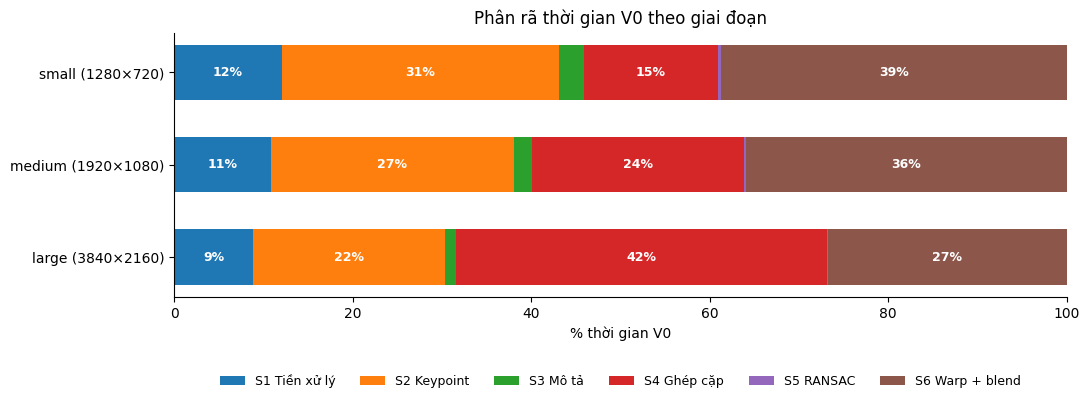

In [11]:
import matplotlib.pyplot as plt

share = SUMMARY[STAGE_COLS].div(SUMMARY[STAGE_COLS].sum(axis=1), axis=0) * 100
growth = None
if "small" in SUMMARY.index:
    growth = SUMMARY[STAGE_COLS + ["Tổng"]].div(SUMMARY.loc["small", STAGE_COLS + ["Tổng"]])
    growth.insert(0, "Pixel", [DIMS[s][0] * DIMS[s][1] / (DIMS["small"][0] * DIMS["small"][1]) for s in growth.index])
    growth.insert(1, "Keypoint²", (SUMMARY["Keypoint"] / SUMMARY.loc["small", "Keypoint"]) ** 2)

def show_hot_stages():
    print("Tỉ lệ thời gian của từng giai đoạn (%):")
    show_table(share.rename(index=RES_LABEL).rename_axis("Độ phân giải").reset_index(),
               {c: "{:.1f}%" for c in STAGE_COLS})
    for size, row in share.iterrows():
        top = row.sort_values(ascending=False)
        print(f"  {RES_LABEL[size]}: {top.index[0]} chiếm {top.iloc[0]:.1f}%, {top.index[1]} chiếm {top.iloc[1]:.1f}%")
    if growth is not None:
        print("\nMức tăng so với small (lần):")
        show_table(growth.rename(index=RES_LABEL).rename_axis("Độ phân giải").reset_index(),
                   {c: "×{:.2f}" for c in growth.columns})

    fig, ax = plt.subplots(figsize=(11, 0.9 * len(share) + 1.6))
    left = np.zeros(len(share))
    labels = [RES_LABEL[s] for s in share.index]
    for i, col in enumerate(STAGE_COLS):
        bars = ax.barh(labels, share[col], left=left, height=0.6, color=plt.cm.tab10(i), label=col)
        for bar, v in zip(bars, share[col]):
            if v >= 4:
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%",
                        ha="center", va="center", color="white", fontsize=9, fontweight="bold")
        left += share[col].to_numpy()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% thời gian V0")
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(ncol=6, bbox_to_anchor=(0.5, -0.25), loc="upper center", frameon=False, fontsize=9)
    ax.set_title("Phân rã thời gian V0 theo giai đoạn")
    plt.tight_layout()
    plt.show()

if not EMBEDDED:
    show_hot_stages()

## 10. Ước lượng theo định luật Amdahl (Mục 5.5)

Nếu các giai đoạn được tăng tốc chiếm tỉ lệ $p$ thời gian của V0 và chạy nhanh hơn $s$ lần, thì speedup end-to-end là

$$S(s) = \frac{1}{(1 - p) + p / s} \;\le\; \frac{1}{1 - p}.$$

Bảng tính $p$, speedup khi GPU nhanh ×10 và ×50, và giới hạn $1/(1-p)$ cho bốn kịch bản: chỉ tăng tốc giai đoạn nặng nhất, hai giai đoạn nặng nhất, mọi giai đoạn trừ RANSAC, và cả 6 giai đoạn. Ở kịch bản cuối $p = 1$ trong phạm vi V0 đo được. Khi đó giới hạn thực tế đến từ thời gian truyền dữ liệu host↔device và phần việc còn lại trên CPU, sẽ đo ở V1.

Biểu đồ vẽ $S(s)$ ở độ phân giải benchmark chính (medium), trục log, nét đứt là giới hạn của từng kịch bản.

Speedup end-to-end theo định luật Amdahl (GPU ×s: các giai đoạn được chọn nhanh hơn s lần):


Độ phân giải,Kịch bản,Giai đoạn tăng tốc,p,GPU ×10,GPU ×50,Giới hạn 1/(1−p)
small (1280×720),Giai đoạn nặng nhất,S6,38.8%,1.54×,1.61×,1.63×
small (1280×720),2 giai đoạn nặng nhất,"S6, S2",69.9%,2.69×,3.17×,3.32×
small (1280×720),Trừ RANSAC (S5),"S1, S2, S3, S4, S6",99.6%,9.69×,42.56×,280.30×
small (1280×720),Cả 6 giai đoạn,"S1, S2, S3, S4, S5, S6",100.0%,10.00×,50.00×,∞
medium (1920×1080),Giai đoạn nặng nhất,S6,36.0%,1.48×,1.54×,1.56×
medium (1920×1080),2 giai đoạn nặng nhất,"S6, S2",63.1%,2.31×,2.62×,2.71×
medium (1920×1080),Trừ RANSAC (S5),"S1, S2, S3, S4, S6",99.7%,9.77×,44.36×,385.51×
medium (1920×1080),Cả 6 giai đoạn,"S1, S2, S3, S4, S5, S6",100.0%,10.00×,50.00×,∞
large (3840×2160),Giai đoạn nặng nhất,S4,41.6%,1.60×,1.69×,1.71×
large (3840×2160),2 giai đoạn nặng nhất,"S4, S6",68.4%,2.60×,3.03×,3.16×


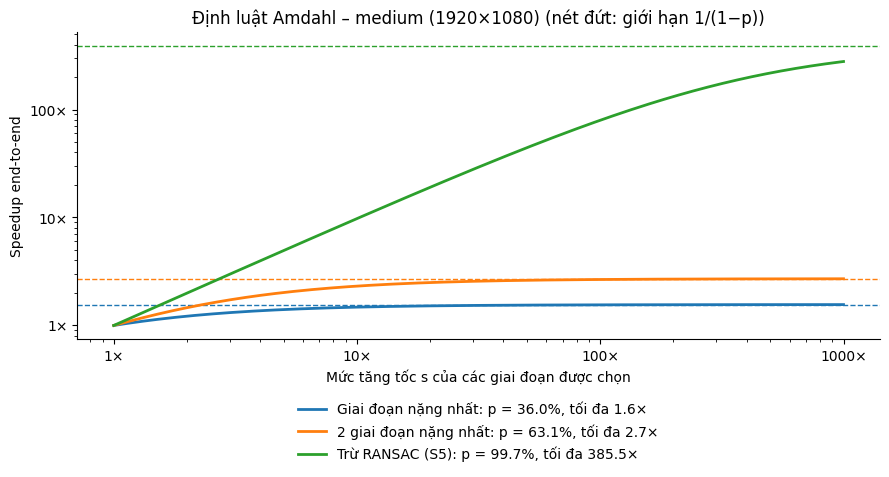

In [12]:
def amdahl(p, s):
    """Speedup end-to-end khi phần chiếm tỉ lệ p được tăng tốc s lần (s = ∞: giới hạn 1 / (1 − p))."""
    return 1 / (1 - p) if np.isinf(s) else 1 / ((1 - p) + p / s)

rows = []
for size, t in SUMMARY[STAGE_COLS].iterrows():
    ranked = list(t.sort_values(ascending=False).index)
    scenarios = {"Giai đoạn nặng nhất": ranked[:1], "2 giai đoạn nặng nhất": ranked[:2],
                 "Trừ RANSAC (S5)": [c for c in STAGE_COLS if c != "S5 RANSAC"], "Cả 6 giai đoạn": STAGE_COLS}
    for name, cols in scenarios.items():
        p = 1.0 if len(cols) == len(STAGE_COLS) else t[cols].sum() / t.sum()
        rows.append({"Độ phân giải": RES_LABEL[size], "Kịch bản": name,
                     "Giai đoạn tăng tốc": ", ".join(c.split()[0] for c in cols), "p": p,
                     "GPU ×10": amdahl(p, 10), "GPU ×50": amdahl(p, 50),
                     "Giới hạn 1/(1−p)": np.inf if p >= 1 else amdahl(p, np.inf)})
AMDAHL = pd.DataFrame(rows)
BENCH = "medium" if "medium" in SUMMARY.index else SUMMARY.index[0]

def show_amdahl():
    speed = lambda v: "∞" if np.isinf(v) else f"{v:.2f}×"
    print("Speedup end-to-end theo định luật Amdahl (GPU ×s: các giai đoạn được chọn nhanh hơn s lần):")
    show_table(AMDAHL, {"p": "{:.1%}", "GPU ×10": speed, "GPU ×50": speed, "Giới hạn 1/(1−p)": speed})

    s = np.logspace(0, 3, 200)
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, r in enumerate(AMDAHL[AMDAHL["Độ phân giải"] == RES_LABEL[BENCH]].itertuples()):
        if r.p >= 1:
            continue   # p = 1: speedup tăng tuyến tính theo s, không có giới hạn
        limit = 1 / (1 - r.p)
        ax.plot(s, [amdahl(r.p, x) for x in s], color=plt.cm.tab10(i), linewidth=2,
                label=f"{r._2}: p = {r.p:.1%}, tối đa {limit:.1f}×")
        ax.axhline(limit, color=plt.cm.tab10(i), linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")   # thang log để thấy rõ cả giới hạn nhỏ (vài lần) lẫn lớn (hàng trăm lần)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.set_xlabel("Mức tăng tốc s của các giai đoạn được chọn")
    ax.set_ylabel("Speedup end-to-end")
    ax.set_title(f"Định luật Amdahl – {RES_LABEL[BENCH]} (nét đứt: giới hạn 1/(1−p))")
    ax.spines[["top", "right"]].set_visible(False)
    # Chú thích đặt dưới trục hoành, ngoài vùng vẽ, để không đè lên đường cong và đường giới hạn
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=1)
    plt.tight_layout()
    plt.show()

if not EMBEDDED:
    show_amdahl()